# Imputation

In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
sys.path.append(str(PROJECT_ROOT))

## Experiment

Define output of experiment:

In [9]:
OUTPUTS = PROJECT_ROOT / "outputs"
OUTPUTS.mkdir(parents=True, exist_ok=True)

Import data, split into train/test and scale on train data.

In [3]:
from src.data import load_ett, chronological_split, scale

train, test = chronological_split(load_ett())
train_s, test_s, scaler = scale(train=train, test=test)

Set location for storing reconstructed datasets.

In [10]:
from src.experiments.artifacts import ReconstructedStore

store = ReconstructedStore(OUTPUTS / "reconstructed")

Initialise experiment.

In [5]:
from src.experiments.imputation import ImputationExperiment
from src.imputers import IMPUTERS

experiment = ImputationExperiment(
    mechanisms=["mar", "mcar", "mnar"],
    proportions=[10, 30, 50],
    seeds=range(10),
    imputer_names=list(IMPUTERS)
)

Run experiment with scaled train data, store reconstructed dataframes and save reconstruction metrics.

In [6]:
recon_df = experiment.run(train=train_s, store=store)
recon_df.to_parquet(OUTPUTS / "reconstruction_metrics.parquet")


## Results

In [7]:
import pandas as pd
df = pd.read_parquet(OUTPUTS / "reconstruction_metrics.parquet")

In [8]:
df.head()

,mechanism,proportion,seed,imputer,reconstruction_rmse,reconstruction_mae
0,mar,10,0,locf,0.049497,0.032298
1,mar,10,0,ks,0.049497,0.032298
2,mar,10,0,arima,0.049497,0.032298
3,mar,10,0,lstm,0.049497,0.032298
4,mar,30,0,locf,0.058453,0.038822


In [9]:
df.groupby(["imputer", "mechanism", "proportion"]).agg(
    rmse=("reconstruction_rmse", "mean"),
    mae=("reconstruction_mae", "mean")
    )

rmse       mae
imputer mechanism proportion                    
arima   mar       10          0.048911  0.032286
                  30          0.058830  0.038996
                  50          0.078174  0.053210
        mcar      10          0.054085  0.034353
                  30          0.061268  0.038359
                  50          0.072965  0.045074
        mnar      10          0.049814  0.033123
                  30          0.059849  0.039895
                  50          0.078907  0.053790
ks      mar       10          0.048911  0.032286
                  30          0.058830  0.038996
                  50          0.078174  0.053210
        mcar      10          0.054085  0.034353
                  30          0.061268  0.038359
                  50          0.072965  0.045074
        mnar      10          0.049814  0.033123
                  30          0.059849  0.039895
                  50          0.078907  0.053790
locf    mar       10          0.048911  0.032286
                  30          0.058830  0.038996
                  50          0.078174  0.053210
        mcar      10          0.054085  0.034353
                  30          0.061268  0.038359
                  50          0.072965  0.045074
        mnar      10          0.049814  0.033123
                  30          0.059849  0.039895
                  50          0.078907  0.053790
lstm    mar       10          0.048911  0.032286
                  30          0.058830  0.038996
                  50          0.078174  0.053210
        mcar      10          0.054085  0.034353
                  30          0.061268  0.038359
                  50          0.072965  0.045074
        mnar      10          0.049814  0.033123
                  30          0.059849  0.039895
                  50          0.078907  0.053790

---

# Testing

In [6]:
from src.experiments.imputation import ImputationExperiment
from src.imputers import IMPUTERS

experiment = ImputationExperiment(
    mechanisms=["mar", "mcar", "mnar"],
    proportions=[10, 30, 50],
    seeds=range(10),
    imputer_names=["mean", "locf", "ks"]
)

In [11]:
TEST_RESULTS = experiment.run(train=train_s, store=store)

c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users\stuwi\Documents\Dissertation\diss_venv\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
c:\Users

In [12]:
TEST_RESULTS_GROUPED = TEST_RESULTS.groupby(["imputer", "mechanism", "proportion"]).agg(
    rmse=("reconstruction_rmse", "mean"),
    mae=("reconstruction_mae", "mean")
    )

In [13]:
TEST_RESULTS_GROUPED

rmse       mae
imputer mechanism proportion                    
ks      mar       10          0.035238  0.023531
                  30          0.042119  0.028243
                  50          0.060891  0.040751
        mcar      10          0.037036  0.024020
                  30          0.039914  0.026227
                  50          0.046734  0.030576
        mnar      10          0.036130  0.024240
                  30          0.043445  0.029063
                  50          0.061681  0.041215
locf    mar       10          0.048911  0.032286
                  30          0.058830  0.038996
                  50          0.078174  0.053210
        mcar      10          0.054085  0.034353
                  30          0.061268  0.038359
                  50          0.072965  0.045074
        mnar      10          0.049814  0.033123
                  30          0.059849  0.039895
                  50          0.078907  0.053790
mean    mar       10          0.144442  0.112215
                  30          0.156675  0.125496
                  50          0.180419  0.150742
        mcar      10          0.147382  0.110098
                  30          0.147117  0.109911
                  50          0.147228  0.110014
        mnar      10          0.143391  0.110934
                  30          0.161636  0.131070
                  50          0.193669  0.167215

In [14]:
mae_df = (
    TEST_RESULTS       # both imputers' per-run rows
      .groupby(["imputer", "mechanism", "proportion"])["reconstruction_mae"]
      .mean()
      .reset_index(name="mae")
)

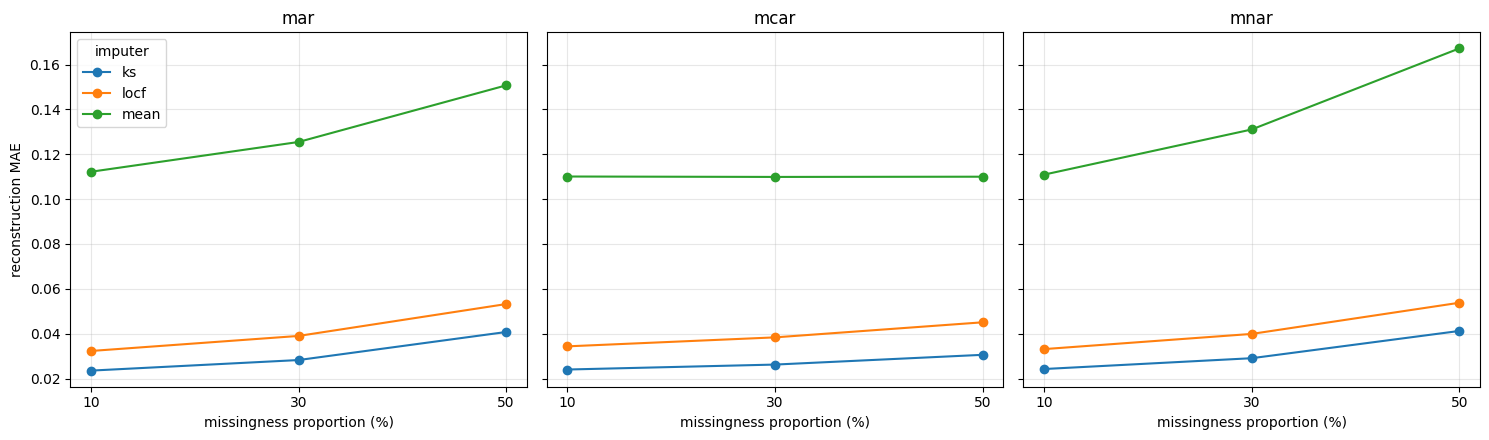

In [15]:
import matplotlib.pyplot as plt
mechanisms = ["mar", "mcar", "mnar"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, mech in zip(axes, mechanisms):
    sub = mae_df[mae_df["mechanism"] == mech]
    for imp, g in sub.groupby("imputer"):
        g = g.sort_values("proportion")
        ax.plot(g["proportion"], g["mae"], marker="o", label=imp)
    ax.set_title(mech)
    ax.set_xlabel("missingness proportion (%)")
    ax.set_xticks([10, 30, 50])
    ax.grid(alpha=0.3)

axes[0].set_ylabel("reconstruction MAE")
axes[0].legend(title="imputer")
plt.tight_layout()
plt.show()

GAP CHECKING

In [9]:
import numpy as np
import pandas as pd
from src.missingness import create_mask

mask = create_mask(train_s, "mcar", 50, 0)      # highest proportion = most/longest gaps
incomplete = train_s.mask(mask)

col = incomplete["OT"]
nan_pos = np.where(col.isna().to_numpy())[0]     # integer positions of NaNs

# split into consecutive runs: a break is where positions jump by >1
runs = np.split(nan_pos, np.where(np.diff(nan_pos) > 1)[0] + 1)
run_lengths = [len(r) for r in runs]

print(pd.Series(run_lengths).value_counts().sort_index())   # distribution of gap lengths
print("longest gap:", max(run_lengths), " total gaps:", len(run_lengths))

1     1567
2      723
3      385
4      187
5      105
6       48
7       22
8        8
9        5
10       1
11       3
Name: count, dtype: int64
longest gap: 11  total gaps: 3054


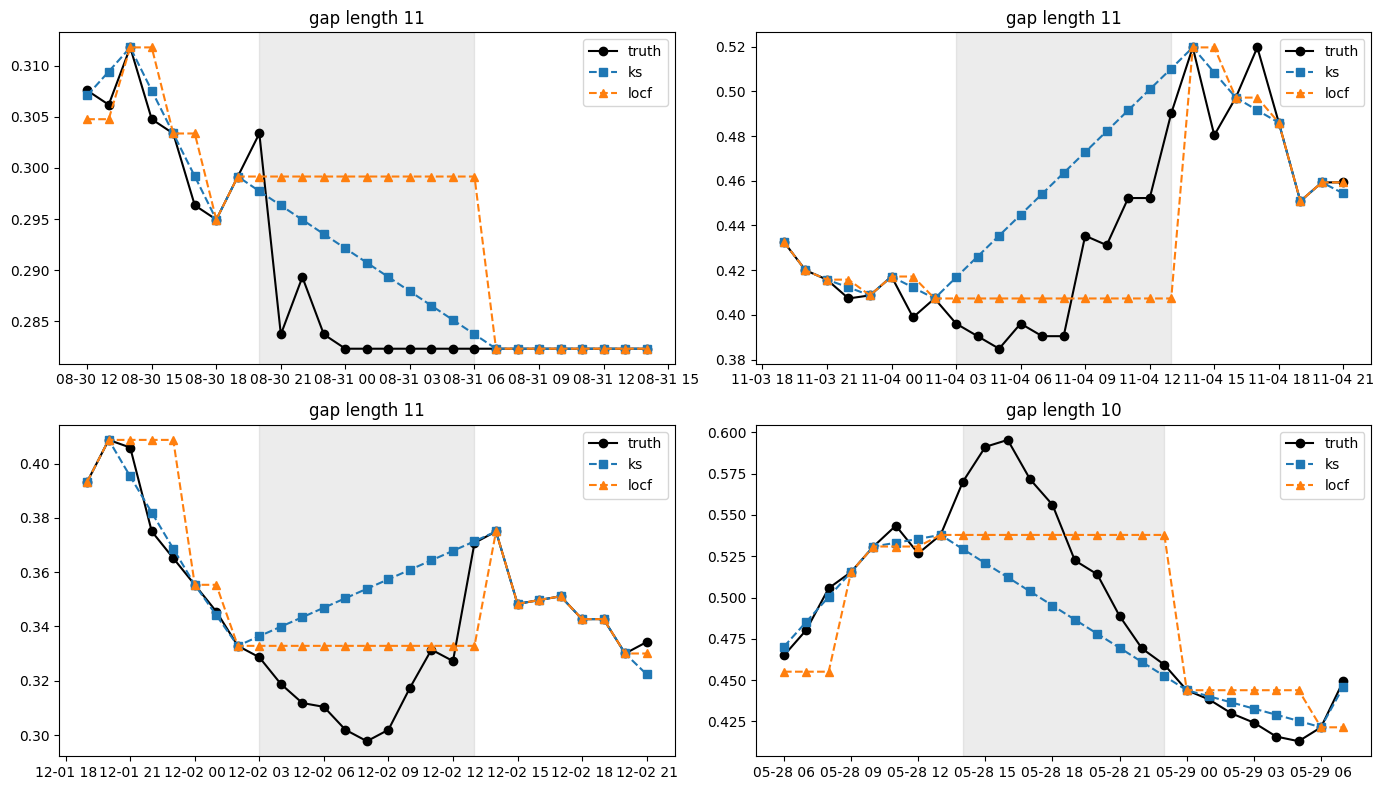

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.missingness import create_mask
from src.imputers import get_imputer

TARGET = "OT"

# One gappy frame — 50% gives the longest runs
mask = create_mask(train_s, "mcar", 50, 0)
incomplete = train_s.mask(mask)

# Impute the same frame both ways
ks_filled   = get_imputer("ks").fit_transform(incomplete)
locf_filled = get_imputer("locf").fit_transform(incomplete)

# Find consecutive-NaN runs in the OT column
col = incomplete[TARGET]
nan_pos = np.where(col.isna().to_numpy())[0]
runs = np.split(nan_pos, np.where(np.diff(nan_pos) > 1)[0] + 1)
order = np.argsort([len(r) for r in runs])[::-1]
longest = [runs[i] for i in order[:4]]        # 4 longest gaps

# Plot a padded window around each
pad = 8
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, r in zip(axes.ravel(), longest):
    lo, hi = max(0, r[0] - pad), min(len(col), r[-1] + pad + 1)
    w = np.arange(lo, hi)
    t = train_s.index[w]

    ax.plot(t, train_s[TARGET].to_numpy()[w], "o-", label="truth", color="black")
    ax.plot(t, ks_filled[TARGET].to_numpy()[w], "s--", label="ks", color="tab:blue")
    ax.plot(t, locf_filled[TARGET].to_numpy()[w], "^--", label="locf", color="tab:orange")
    # shade the gap
    ax.axvspan(train_s.index[r[0]], train_s.index[r[-1]], color="grey", alpha=0.15)
    ax.set_title(f"gap length {len(r)}")
    ax.legend()

plt.tight_layout()
plt.show()